<a href="https://colab.research.google.com/github/cmpquilatan21/DATAthon_2026_-FirstPlaceInbound-/blob/main/heatmap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_481/1387753950.py:5: DtypeWarning: Columns (29,30,31,32,33,34,35,36,37,38,39,40,41) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("US_Accidents_cleaned.csv")


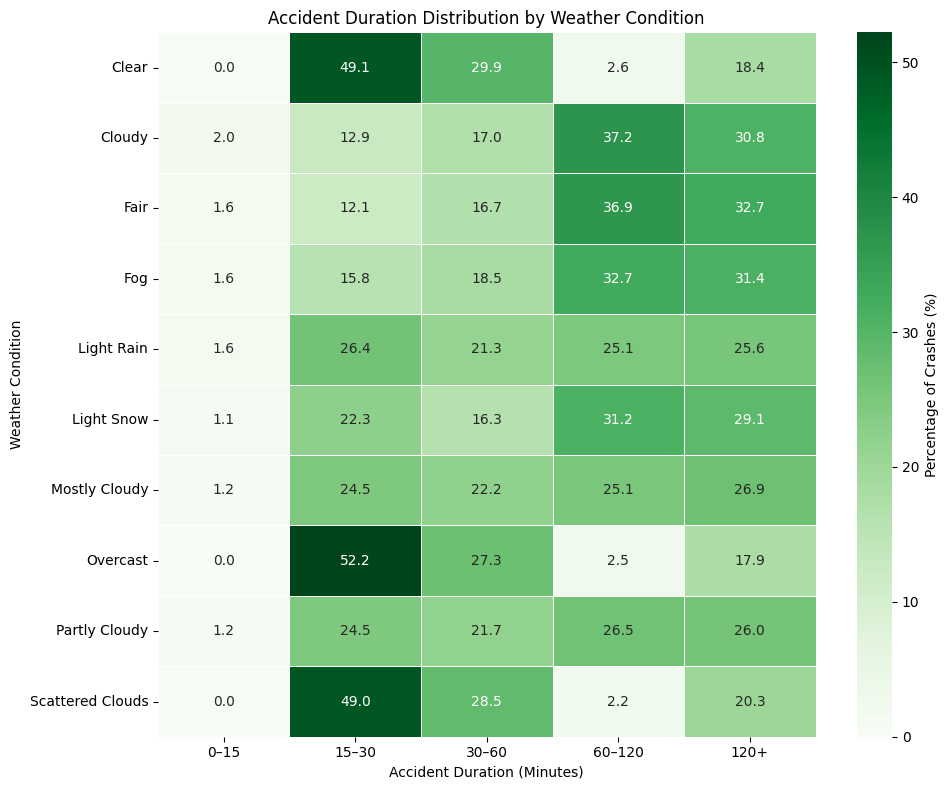

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("US_Accidents_cleaned.csv")

top_weather = df['Weather_Condition'].value_counts().head(10).index
filtered_df = df[df['Weather_Condition'].isin(top_weather)].copy()

filtered_df['Duration_Range'] = pd.cut(
    filtered_df['Accident_Duration_Minutes'],
    bins=[0, 15, 30, 60, 120, float('inf')],
    labels=['0–15', '15–30', '30–60', '60–120', '120+']
)

heatmap_data = pd.crosstab(
    filtered_df['Weather_Condition'],
    filtered_df['Duration_Range'],
    normalize='index'
) * 100

plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='Greens',
    linewidths=0.5,
    cbar_kws={'label': 'Percentage of Crashes (%)'}
)

plt.title('Accident Duration Distribution by Weather Condition')
plt.xlabel('Accident Duration (Minutes)')
plt.ylabel('Weather Condition')

plt.tight_layout()
plt.show()